In [1]:
import os
import glob
import pandas as pd
import re
from typing import Optional, Tuple, Iterable, List
import matplotlib.pyplot as plt
import PIL.Image as Image
from tqdm import tqdm
import numpy as np

In [2]:
ROOT_DIR = "/home/klymy/data/cam4_revB/yolo_dataset"
SUFFIX_VAL = "labels/val"
SUFFIX_TRAIN = "labels/train"
SUFFIX_IMAGES_VAL = "images/val"
SUFFIX_IMAGES_TRAIN = "images/train"

BATCHES = [
    "batch1_10_margin_15_bg_wb_alif",
    "batch11_margin_15_wb_alif",
    "batch12_margin_15_wb_alif",
]

In [3]:
labels_paths = {}
for batch in BATCHES:
    train_path = os.path.join(ROOT_DIR, batch, SUFFIX_TRAIN)
    val_path = os.path.join(ROOT_DIR, batch, SUFFIX_VAL)
    labels_paths[batch] = glob.glob(os.path.join(train_path, "*.txt")) + glob.glob(os.path.join(val_path, "*.txt"))
    print(f"Found {len(labels_paths[batch])} label files in {batch}")

print()
imgs_paths = {}
for batch in BATCHES:
    train_path = os.path.join(ROOT_DIR, batch, SUFFIX_IMAGES_TRAIN)
    val_path = os.path.join(ROOT_DIR, batch, SUFFIX_IMAGES_VAL)
    imgs_paths[batch] = glob.glob(os.path.join(train_path, "*.jpg")) + glob.glob(os.path.join(val_path, "*.jpg"))
    print(f"Found {len(labels_paths[batch])} image files in {batch}")

Found 7465 label files in batch1_10_margin_15_bg_wb_alif
Found 7320 label files in batch11_margin_15_wb_alif
Found 5229 label files in batch12_margin_15_wb_alif

Found 7465 image files in batch1_10_margin_15_bg_wb_alif
Found 7320 image files in batch11_margin_15_wb_alif
Found 5229 image files in batch12_margin_15_wb_alif


In [4]:
# 1) pattern with H_cam_### and env after that
_RE_CAM = re.compile(
    r"""
    _H_cam_(?P<height>\d+) # height, e.g. 234
    _(?P<env>[A-Za-z][A-Za-z0-9_]*) # env, e.g. spacesbooth / menivimOS_1
    _
    """,
    re.VERBOSE
)


# 2) pattern with H### and env after that (no cam)
_RE_NO_CAM = re.compile(
    r"""
    _H(?P<height>\d+) # height, e.g. 260
    _(?P<env>[A-Za-z][A-Za-z0-9_]*)# env
    _
    """,
    re.VERBOSE
)


def extract_height_env(filename: str) -> Optional[Tuple[int, str]]:
    """
    Returns (height:int, env:str) or None if cannot parse.
    """
    base = os.path.basename(filename)


    m = _RE_CAM.search(base)
    if not m:
        m = _RE_NO_CAM.search(base)
    if not m:
        return None

    height = int(m.group("height"))
    env = m.group("env")
    return height, env


def extract_all(files: Iterable[str]) -> List[Tuple[int, str]]:
    out = []
    for f in files:
        t = extract_height_env(f)
        if t is not None:
            out.append(t)
    return out

In [5]:
def read_labels(labels_paths):
    # Read YOLO labels from all files in labels_paths
    # Each line: class_id x_center y_center width height (normalized)
    labels = []
    for label_path in labels_paths:
        with open(label_path, 'r') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split()
                if len(parts) < 5:
                    continue
                class_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:5])
                labels.append({
                    'label_path': label_path,
                    'class_id': class_id,
                    'x_center': x_center,
                    'y_center': y_center,
                    'width': width,
                    'height': height,
                })

    return labels


In [6]:
heights = {}
for batch in BATCHES:
    heights[batch] = pd.DataFrame(extract_all(labels_paths[batch]), columns=["height", "env"])
    heights[batch] = heights[batch][heights[batch]["height"] > 100]  # filter out bad data

In [7]:
labesl = {}
for batch in BATCHES:
    labesl[batch] = read_labels(labels_paths[batch])

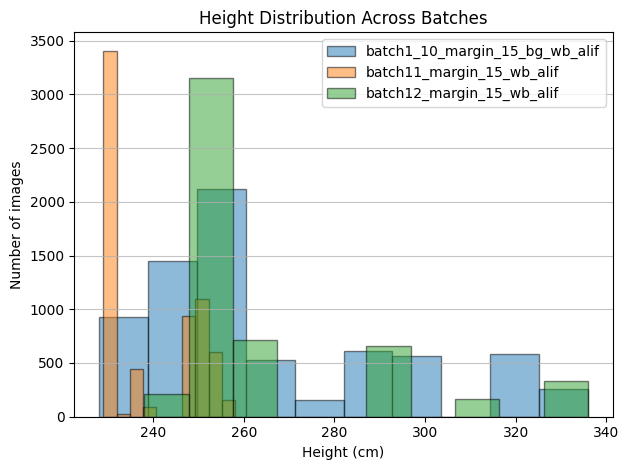

In [8]:
for batch in BATCHES:
    tmp_df = heights[batch]
    plt.hist(tmp_df["height"], bins=10, alpha=0.5, label=batch, edgecolor='black')

plt.xlabel("Height (cm)")
plt.ylabel("Number of images")
plt.title("Height Distribution Across Batches")
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.savefig("height_distribution_histogram.png")

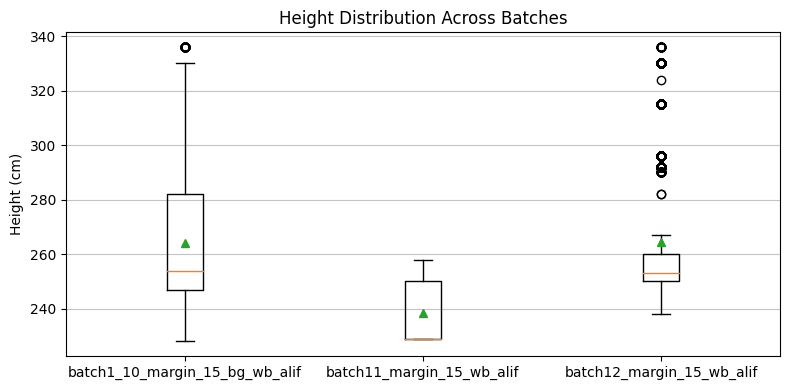

In [9]:
plt.figure(figsize=(8, 4))
for batch in BATCHES:
    tmp_df = heights[batch]
    plt.boxplot(tmp_df["height"], labels=[batch], positions=[BATCHES.index(batch)+1], showmeans=True)

plt.ylabel("Height (cm)")
plt.title("Height Distribution Across Batches")
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.savefig("height_distribution_boxplot.png")

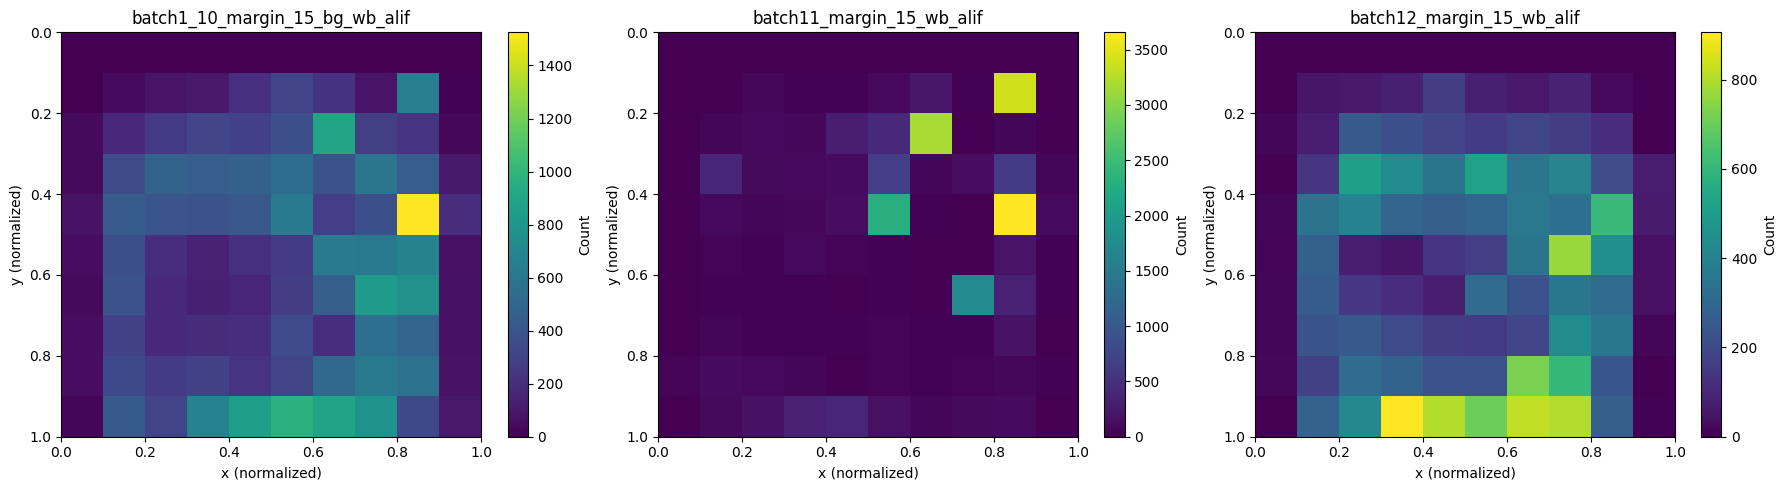

In [10]:
plt.figure(figsize=(18, 5))
for batch in BATCHES:
    labels = labesl[batch]
    # 2D histogram of leg positions across the frame
    # Approximate leg position as bottom-center of the bbox
    x_legs = [item['x_center'] for item in labels]
    y_legs = [item['y_center'] + 0.5 * item['height'] for item in labels]

    plt.subplot(1, len(BATCHES), BATCHES.index(batch) + 1)
    plt.hist2d(x_legs, y_legs, bins=10, range=[[0, 1], [0, 1]])#, cmap='magma')
    plt.colorbar(label='Count')
    plt.title(batch)
    plt.xlabel('x (normalized)')
    plt.ylabel('y (normalized)')
    plt.ylim(1, 0)
    plt.tight_layout()

plt.savefig("leg_position_heatmaps.png")

In [11]:
ENV_IMG_ROOT = "env_images"
os.makedirs(ENV_IMG_ROOT, exist_ok=True)

for batch in BATCHES:
    tmp_dir = os.path.join(ENV_IMG_ROOT, batch)
    os.makedirs(tmp_dir, exist_ok=True)
    
    tmp_df = heights[batch]
    img_names = imgs_paths[batch]

    # detection counts per label file
    counts_by_label = {}
    for item in labesl[batch]:
        lp = item['label_path']
        counts_by_label[lp] = counts_by_label.get(lp, 0) + 1

    n = len(tmp_df["env"].unique())

    for env_name in tqdm(tmp_df["env"].unique(), desc=f"Processing {batch} ({n} envs)"):
        subset = [i for i in img_names if f"_{env_name}_" in i]
        if not subset:
            continue

        # Height statistics from parsed filenames
        env_heights = tmp_df.loc[tmp_df["env"] == env_name, "height"].tolist()
        env_heights = [h for h in env_heights if h is not None]
        if env_heights:
            min_h = float(np.min(env_heights))
            max_h = float(np.max(env_heights))
            mean_h = float(np.mean(env_heights))
            median_h = float(np.median(env_heights))
        else:
            min_h = max_h = mean_h = median_h = 0.0

        # Detection statistics per image (from labels)
        det_counts = []
        for img_path in subset:
            label_path = img_path.replace('/images/', '/labels/').replace('.jpg', '.txt')
            det_counts.append(counts_by_label.get(label_path, 0))

        if det_counts:
            max_det = float(np.max(det_counts))
            mean_det = float(np.mean(det_counts))
            median_det = float(np.median(det_counts))
        else:
            max_det = mean_det = median_det = 0.0

        example_img_path = subset[0]
        img = Image.open(example_img_path)
        plt.imshow(img)
        title_line1 = f"{env_name} ({len(subset)} images) | H u_count min/med/mean/max:{np.unique(env_heights).shape[0]} {min_h:.0f}/{median_h:.0f}/{mean_h:.1f}/{max_h:.0f}"
        title_line2 = f"D med/mean/max: {median_det:.1f}/{mean_det:.1f}/{max_det:.0f}"
        plt.title(title_line1 + '\n' + title_line2, fontsize=9)
        plt.axis("off")
        plt.tight_layout()
        plt.savefig(os.path.join(tmp_dir, f"{env_name}.jpg"))
        plt.close()


Processing batch1_10_margin_15_bg_wb_alif (72 envs): 100%|██████████| 72/72 [00:07<00:00,  9.05it/s]
Processing batch12_margin_15_wb_alif (182 envs): 100%|██████████| 182/182 [00:19<00:00,  9.13it/s]


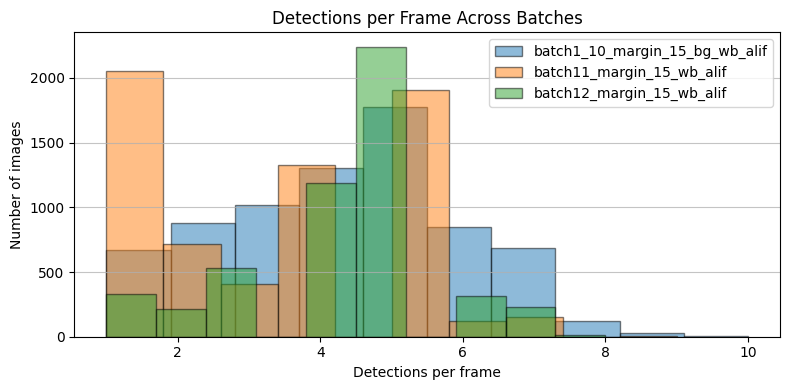

In [12]:
# Detections per frame histogram across batches
plt.figure(figsize=(8, 4))
for batch in BATCHES:
    labels = labesl[batch]
    # count detections per label file
    counts_by_label = {}
    for item in labels:
        lp = item['label_path']
        counts_by_label[lp] = counts_by_label.get(lp, 0) + 1

    det_counts = list(counts_by_label.values())
    plt.hist(det_counts, bins=10, alpha=0.5, label=batch, edgecolor='black')

plt.xlabel('Detections per frame')
plt.ylabel('Number of images')
plt.title('Detections per Frame Across Batches')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.savefig("detections_per_frame_histogram.png")
